# Feature Engineering — Cosmetics Capstone

This notebook continues from the files saved in `prepared`. It does not rerun Preprocessing or EDA.

**Goal:** Build two experimental versions of the Feature Matrix and compare them later with the original Baseline:

1. **Baseline:** The original 1,291 ingredient features + five skin-type one-hot features.
2. **Feature Set A:** Baseline + two ingredient-coverage features: total ingredient count and the ratio of ingredients recognized by the training vocabulary.
3. **Feature Set B:** Feature Set A + optional product information: log-transformed price, Rank, a missing-Rank indicator, and product category `Label` using one-hot encoding.

> **Methodological note:** The current target, `target_score_percent`, is a statistical proxy created during preprocessing from ingredient and skin-label associations. It is not a medical compatibility measurement or a validated probability. Any later evaluation will measure only how well a model reproduces this proxy.

**Important:** Do not use `original_binary_tag` as a feature because it is an original label used to create the target. Do not use product name, brand, or `source_row` as model inputs.

## Cell 1 — Imports and project paths

Import the required libraries and look for the `prepared` folder in the current working directory or its parent.

In [3]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from sklearn.preprocessing import StandardScaler

# Locate the project folder. Normally VS Code opens the project root.
possible_roots = [Path.cwd(), Path.cwd().parent]
PROJECT_DIR = next(
    (path for path in possible_roots if (path / "prepared").is_dir()),
    None
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not find a 'prepared' folder. Open the capstone project folder in VS Code."
    )

DATA_DIR = PROJECT_DIR / "prepared"
OUTPUT_DIR = PROJECT_DIR / "feature_engineering_output"

print("Project folder:", PROJECT_DIR)
print("Prepared folder exists:", DATA_DIR.is_dir())
print("Output folder:", OUTPUT_DIR)

Project folder: c:\Users\DRT\Downloads\capstone project
Prepared folder exists: True
Output folder: c:\Users\DRT\Downloads\capstone project\feature_engineering_output


## Cell 2 — Load the saved data

Load the metadata, quality report, cleaned data, matrices, and manifests. The skin one-hot feature count is read from `skin_onehot_order` or `skin_columns` in the metadata, rather than from the nonexistent `skin_onehot_features` key.

In [5]:
# Load metadata files
with open(DATA_DIR / "vocabulary.json", "r", encoding="utf-8") as file:
    metadata = json.load(file)

with open(DATA_DIR / "quality_report.json", "r", encoding="utf-8") as file:
    quality_report = json.load(file)

# Load cleaned product-level data
clean_df = pd.read_csv(DATA_DIR / "clean_cosmetics.csv")

# Use the actual keys available in vocabulary.json
ingredient_vocabulary = metadata["vocabulary"]
skin_types = metadata.get("skin_onehot_order", metadata["skin_columns"])
n_ingredient_features = int(metadata["ingredient_feature_count"])
n_skin_features = len(skin_types)
n_baseline_features = n_ingredient_features + n_skin_features

# Load the three saved splits
X_train = sparse.load_npz(DATA_DIR / "X_train.npz").tocsr()
X_val = sparse.load_npz(DATA_DIR / "X_val.npz").tocsr()
X_test = sparse.load_npz(DATA_DIR / "X_test.npz").tocsr()

y_train = np.load(DATA_DIR / "y_train.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

train_manifest = pd.read_csv(DATA_DIR / "train_manifest.csv")
val_manifest = pd.read_csv(DATA_DIR / "val_manifest.csv")
test_manifest = pd.read_csv(DATA_DIR / "test_manifest.csv")

print("Cleaned data:", clean_df.shape)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Ingredient features:", n_ingredient_features)
print("Skin-type features:", n_skin_features)
print("Total baseline features:", n_baseline_features)

Cleaned data: (1266, 15)
Train: (3115, 1296)
Validation: (665, 1296)
Test: (670, 1296)
Ingredient features: 1291
Skin-type features: 5
Total baseline features: 1296


## Cell 3 — Check that the saved files agree

This cell checks that the matrix dimensions, targets, and manifests agree, and that the final five columns represent exactly one skin type per row.

In [6]:
# Check that source_row identifies one cleaned product only
assert clean_df["source_row"].is_unique, "source_row is not unique in clean_cosmetics.csv"

split_objects = {
    "train": (X_train, y_train, train_manifest),
    "validation": (X_val, y_val, val_manifest),
    "test": (X_test, y_test, test_manifest),
}

for split_name, (X, y, manifest) in split_objects.items():
    assert X.shape[1] == n_baseline_features, (
        f"Unexpected number of baseline features in {split_name}: {X.shape[1]}"
    )
    assert X.shape[0] == len(y) == len(manifest), (
        f"Rows do not match in {split_name}"
    )
    assert np.isfinite(y).all(), f"Non-finite target found in {split_name}"
    assert np.allclose(
        manifest["target_score_percent"].to_numpy(), y, atol=1e-5
    ), f"Manifest targets do not match y_{split_name}"

    # Each product is expanded into the five skin types in the saved order.
    expected_skin_order = np.tile(skin_types, manifest["source_row"].nunique())
    assert np.array_equal(
        manifest["skin_type"].astype(str).to_numpy(), expected_skin_order
    ), f"Skin-type row order is unexpected in {split_name}"

    # Each row must have exactly one active skin-type one-hot feature.
    skin_block = X[:, n_ingredient_features:n_baseline_features]
    skin_row_sums = np.asarray(skin_block.sum(axis=1)).ravel()
    assert np.all(skin_row_sums == 1), f"Invalid skin one-hot rows in {split_name}"

print("All integrity checks passed.")
print("Metadata feature count:", n_baseline_features)
print("Quality report feature count:", quality_report["total_features"])

All integrity checks passed.
Metadata feature count: 1296
Quality report feature count: 1296


## Cell 4 — Join product information to each split

The `manifest` files contain a `source_row` for each row (product × skin type), while `clean_cosmetics.csv` contains product details such as `Label`, `Price`, `Rank_clean`, and `n_ing`.

Join them using `source_row`. Do not use `Brand` or `Name` as features; keep them only for identification and auditing.

In [7]:
PRODUCT_COLUMNS = ["source_row", "Label", "Price", "Rank_clean", "n_ing"]
product_lookup = clean_df[PRODUCT_COLUMNS].copy()


def attach_product_data(manifest, split_name):
    """Attach product-level fields to each expanded product/skin row."""
    enriched = manifest.merge(
        product_lookup,
        on="source_row",
        how="left",
        validate="many_to_one"
    )

    if enriched["n_ing"].isna().any():
        missing_ids = enriched.loc[enriched["n_ing"].isna(), "source_row"].unique()
        raise ValueError(
            f"Some source_row values in {split_name} were not found in clean_cosmetics.csv: "
            f"{missing_ids[:10]}"
        )

    return enriched

train_meta = attach_product_data(train_manifest, "train")
val_meta = attach_product_data(val_manifest, "validation")
test_meta = attach_product_data(test_manifest, "test")

print("Train metadata rows:", len(train_meta))
print("Validation metadata rows:", len(val_meta))
print("Test metadata rows:", len(test_meta))
print("Product categories in training:", sorted(train_meta["Label"].dropna().unique()))

Train metadata rows: 3115
Validation metadata rows: 665
Test metadata rows: 670
Product categories in training: ['Cleanser', 'Eye cream', 'Face Mask', 'Moisturizer', 'Sun protect', 'Treatment']


## Cell 5 — Create ingredient coverage features

The ingredient vectorizer learned its vocabulary from Train only. Therefore, some ingredients in each product may not appear in the 1,291 ingredient features.

Create two main features:

- `n_ingredients_total`: total number of ingredients after cleaning, taken from `n_ing`.
- `ingredient_coverage_ratio`: ratio of ingredients that the training vocabulary can represent.

Also calculate `n_ingredients_unknown` for analysis and quality checks, but do not add it to the same feature matrix at the same time because it is mathematically derived from the total and recognized ingredient counts.

In [8]:
def add_ingredient_coverage_features(X, enriched_manifest, split_name):
    """Create product-level ingredient coverage diagnostics aligned to X rows."""
    ingredient_matrix = X[:, :n_ingredient_features].tocsr()

    # Binary CountVectorizer features: number of active columns = recognized ingredients.
    known_count = np.asarray(ingredient_matrix.getnnz(axis=1)).ravel().astype(int)
    total_count = enriched_manifest["n_ing"].to_numpy(dtype=int)
    unknown_count = total_count - known_count

    if np.any(unknown_count < 0):
        raise ValueError(
            f"Known ingredient count exceeds total ingredients in {split_name}. "
            "Check matrix/manifest alignment."
        )

    coverage_ratio = np.divide(
        known_count,
        total_count,
        out=np.zeros(len(total_count), dtype=float),
        where=total_count > 0
    )

    result = enriched_manifest.copy()
    result["n_ingredients_total"] = total_count
    result["n_ingredients_known"] = known_count
    result["n_ingredients_unknown"] = unknown_count
    result["ingredient_coverage_ratio"] = coverage_ratio
    result["ingredient_unknown_ratio"] = 1.0 - coverage_ratio

    return result

train_meta = add_ingredient_coverage_features(X_train, train_meta, "train")
val_meta = add_ingredient_coverage_features(X_val, val_meta, "validation")
test_meta = add_ingredient_coverage_features(X_test, test_meta, "test")

print(train_meta[[
    "Name", "skin_type", "n_ingredients_total",
    "n_ingredients_known", "n_ingredients_unknown",
    "ingredient_coverage_ratio"
]].head(10).to_string(index=False))

                    Name   skin_type  n_ingredients_total  n_ingredients_known  n_ingredients_unknown  ingredient_coverage_ratio
         Crème de la Mer Combination                   42                   41                      1                    0.97619
         Crème de la Mer         Dry                   42                   41                      1                    0.97619
         Crème de la Mer      Normal                   42                   41                      1                    0.97619
         Crème de la Mer        Oily                   42                   41                      1                    0.97619
         Crème de la Mer   Sensitive                   42                   41                      1                    0.97619
Facial Treatment Essence Combination                    7                    7                      0                    1.00000
Facial Treatment Essence         Dry                    7                    7                   

## Cell 6 — Summarize ingredient coverage

Show the summary at the unique-product level, rather than counting the five repeated skin-type rows for each product.

In [9]:
def split_coverage_summary(meta, split_name):
    products = meta.drop_duplicates("source_row")
    return {
        "split": split_name,
        "products": len(products),
        "mean_total_ingredients": products["n_ingredients_total"].mean(),
        "mean_known_ingredients": products["n_ingredients_known"].mean(),
        "mean_unknown_ingredients": products["n_ingredients_unknown"].mean(),
        "mean_coverage_ratio": products["ingredient_coverage_ratio"].mean(),
        "products_with_zero_known_ingredients": int(
            (products["n_ingredients_known"] == 0).sum()
        ),
    }

coverage_summary = pd.DataFrame([
    split_coverage_summary(train_meta, "Train"),
    split_coverage_summary(val_meta, "Validation"),
    split_coverage_summary(test_meta, "Test"),
])

coverage_summary.round(3)

,split,products,mean_total_ingredients,mean_known_ingredients,mean_unknown_ingredients,mean_coverage_ratio,products_with_zero_known_ingredients
0,Train,623,35.804,31.005,4.799,0.838,9
1,Validation,133,32.729,26.504,6.226,0.778,3
2,Test,134,33.649,27.306,6.343,0.802,0


## Cell 7 — Visualize ingredient coverage

The plot shows the distribution of the ratio of ingredients recognized by the training vocabulary for each split. This is feature analysis, not model training.

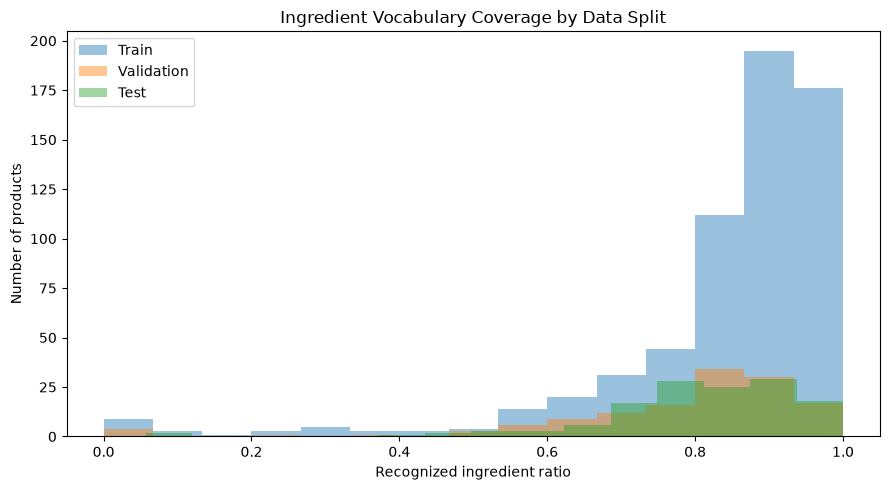

In [10]:
plt.figure(figsize=(9, 5))

for split_name, meta in [
    ("Train", train_meta),
    ("Validation", val_meta),
    ("Test", test_meta),
]:
    unique_products = meta.drop_duplicates("source_row")
    plt.hist(
        unique_products["ingredient_coverage_ratio"],
        bins=15,
        alpha=0.45,
        label=split_name
    )

plt.title("Ingredient Vocabulary Coverage by Data Split")
plt.xlabel("Recognized ingredient ratio")
plt.ylabel("Number of products")
plt.legend()
plt.tight_layout()
plt.show()

## Cell 8 — Prepare numeric and categorical product features

Prepare a second experimental set of product information:

**Numeric features:**
- `n_ingredients_total`
- `ingredient_coverage_ratio`
- `log_price = log(1 + Price)` to reduce potential price skew.
- `rank_clean` after imputing missing values with the Train median.
- `rank_missing` to preserve the information that Rank was missing.

**Categorical feature:**
- `Label` using one-hot encoding.

Exclude `Brand`, `Name`, and `source_row` from model inputs. Exclude `original_binary_tag` because it is not an independent feature; it is an original label used to create the target.

In [11]:
# Convert product fields to numeric values safely.
for meta in (train_meta, val_meta, test_meta):
    meta["Price"] = pd.to_numeric(meta["Price"], errors="coerce")
    meta["Rank_clean"] = pd.to_numeric(meta["Rank_clean"], errors="coerce")

    if (meta["Price"].dropna() < 0).any():
        raise ValueError("Price contains negative values; log1p cannot be applied safely.")

    meta["log_price"] = np.log1p(meta["Price"])
    meta["rank_missing"] = meta["Rank_clean"].isna().astype(np.float32)

# Learn the Rank imputation value from TRAIN only.
rank_median_train = float(train_meta["Rank_clean"].median())
if not np.isfinite(rank_median_train):
    raise ValueError("Could not calculate the training median for Rank_clean.")

for meta in (train_meta, val_meta, test_meta):
    meta["rank_clean_imputed"] = meta["Rank_clean"].fillna(rank_median_train)

# Numeric columns that will be standardized using TRAIN only.
NUMERIC_FEATURES = [
    "n_ingredients_total",
    "ingredient_coverage_ratio",
    "log_price",
    "rank_clean_imputed",
]

# Learn category columns from TRAIN only; unknown validation/test categories become all-zero.
train_labels = train_meta["Label"].fillna("__MISSING__").astype(str)
train_label_dummies = pd.get_dummies(
    train_labels,
    prefix="Label",
    dtype=np.float32
)
label_dummy_columns = train_label_dummies.columns.tolist()


def encode_labels(meta):
    labels = meta["Label"].fillna("__MISSING__").astype(str)
    dummies = pd.get_dummies(labels, prefix="Label", dtype=np.float32)
    dummies = dummies.reindex(columns=label_dummy_columns, fill_value=0)
    return sparse.csr_matrix(dummies.to_numpy(dtype=np.float32))

label_train = sparse.csr_matrix(train_label_dummies.to_numpy(dtype=np.float32))
label_val = encode_labels(val_meta)
label_test = encode_labels(test_meta)

print("Numeric engineered features:", NUMERIC_FEATURES)
print("Product category features:", label_dummy_columns)
print("Training Rank median used for imputation:", round(rank_median_train, 3))

Numeric engineered features: ['n_ingredients_total', 'ingredient_coverage_ratio', 'log_price', 'rank_clean_imputed']
Product category features: ['Label_Cleanser', 'Label_Eye cream', 'Label_Face Mask', 'Label_Moisturizer', 'Label_Sun protect', 'Label_Treatment']
Training Rank median used for imputation: 4.3


## Cell 9 — Scale numeric features using Train only

Use `StandardScaler` after imputing Rank. Fit the scaler on Train only, then transform Validation and Test so information from evaluation splits cannot leak into training.

In [12]:
scaler = StandardScaler()

train_numeric = train_meta[NUMERIC_FEATURES].to_numpy(dtype=np.float64)
val_numeric = val_meta[NUMERIC_FEATURES].to_numpy(dtype=np.float64)
test_numeric = test_meta[NUMERIC_FEATURES].to_numpy(dtype=np.float64)

train_numeric_scaled = scaler.fit_transform(train_numeric).astype(np.float32)
val_numeric_scaled = scaler.transform(val_numeric).astype(np.float32)
test_numeric_scaled = scaler.transform(test_numeric).astype(np.float32)

assert np.isfinite(train_numeric_scaled).all()
assert np.isfinite(val_numeric_scaled).all()
assert np.isfinite(test_numeric_scaled).all()

print("Scaler fitted on Train rows:", scaler.n_samples_seen_)
print("Scaled numeric matrix shapes:")
print("Train:", train_numeric_scaled.shape)
print("Validation:", val_numeric_scaled.shape)
print("Test:", test_numeric_scaled.shape)

Scaler fitted on Train rows: 3115.0
Scaled numeric matrix shapes:
Train: (3115, 4)
Validation: (665, 4)
Test: (670, 4)


## Cell 10 — Build the two feature-engineering variants

**Feature Set A:** Add only two features to the Baseline:
1. `n_ingredients_total`
2. `ingredient_coverage_ratio`

**Feature Set B:** Add the numeric features, `rank_missing`, and six one-hot columns for product category.

Keep the original Baseline unchanged so the experiments can be compared after training.

In [13]:
def to_sparse_matrix(values):
    """Convert one- or two-dimensional numeric data to a CSR matrix."""
    array = np.asarray(values, dtype=np.float32)
    if array.ndim == 1:
        array = array.reshape(-1, 1)
    return sparse.csr_matrix(array)


def build_feature_variants(X_base, numeric_scaled, rank_missing_values, label_matrix):
    # Feature Set A: two ingredient coverage features only.
    ingredient_stats = to_sparse_matrix(numeric_scaled[:, :2])
    X_stats = sparse.hstack(
        [X_base, ingredient_stats],
        format="csr",
        dtype=np.float32
    )

    # Feature Set B: all four numeric features + rank-missing flag + product category.
    rank_missing = to_sparse_matrix(rank_missing_values)
    X_full = sparse.hstack(
        [X_base, to_sparse_matrix(numeric_scaled), rank_missing, label_matrix],
        format="csr",
        dtype=np.float32
    )
    return X_stats, X_full

X_train_fe_stats, X_train_fe_full = build_feature_variants(
    X_train, train_numeric_scaled,
    train_meta["rank_missing"].to_numpy(), label_train
)
X_val_fe_stats, X_val_fe_full = build_feature_variants(
    X_val, val_numeric_scaled,
    val_meta["rank_missing"].to_numpy(), label_val
)
X_test_fe_stats, X_test_fe_full = build_feature_variants(
    X_test, test_numeric_scaled,
    test_meta["rank_missing"].to_numpy(), label_test
)

print("Feature Set A (Baseline + Ingredient Statistics):")
print("Train:", X_train_fe_stats.shape)
print("Validation:", X_val_fe_stats.shape)
print("Test:", X_test_fe_stats.shape)

print("\nFeature Set B (A + Product Context):")
print("Train:", X_train_fe_full.shape)
print("Validation:", X_val_fe_full.shape)
print("Test:", X_test_fe_full.shape)

Feature Set A (Baseline + Ingredient Statistics):
Train: (3115, 1298)
Validation: (665, 1298)
Test: (670, 1298)

Feature Set B (A + Product Context):
Train: (3115, 1307)
Validation: (665, 1307)
Test: (670, 1307)


## Cell 11 — Validate the new matrices

Check that:
- The number of rows has not changed.
- Train, Validation, and Test have the same number of columns within each experiment.
- The original targets are unchanged.
- The new numeric matrices contain no non-finite values.
- The Baseline has not been modified.

In [14]:
# Row and column consistency
assert X_train_fe_stats.shape == (len(y_train), n_baseline_features + 2)
assert X_val_fe_stats.shape == (len(y_val), n_baseline_features + 2)
assert X_test_fe_stats.shape == (len(y_test), n_baseline_features + 2)

expected_full_features = n_baseline_features + len(NUMERIC_FEATURES) + 1 + len(label_dummy_columns)
assert X_train_fe_full.shape == (len(y_train), expected_full_features)
assert X_val_fe_full.shape == (len(y_val), expected_full_features)
assert X_test_fe_full.shape == (len(y_test), expected_full_features)

# Original targets remain unchanged.
assert np.allclose(y_train, train_manifest["target_score_percent"].to_numpy(), atol=1e-5)
assert np.allclose(y_val, val_manifest["target_score_percent"].to_numpy(), atol=1e-5)
assert np.allclose(y_test, test_manifest["target_score_percent"].to_numpy(), atol=1e-5)

# The new sparse matrices contain only finite stored values.
for matrix in [
    X_train_fe_stats, X_val_fe_stats, X_test_fe_stats,
    X_train_fe_full, X_val_fe_full, X_test_fe_full,
]:
    assert np.isfinite(matrix.data).all()

print("All Feature Engineering checks passed.")
print("Baseline feature count:", n_baseline_features)
print("Feature Set A count:", X_train_fe_stats.shape[1])
print("Feature Set B count:", X_train_fe_full.shape[1])

All Feature Engineering checks passed.
Baseline feature count: 1296
Feature Set A count: 1298
Feature Set B count: 1307


## Cell 12 — Inspect the engineered feature values

This is a product-level sample, so remove duplicates caused by the five skin-type rows for display only.

In [15]:
display_columns = [
    "Brand", "Name", "Label", "Price", "Rank_clean",
    "n_ingredients_total", "n_ingredients_known",
    "n_ingredients_unknown", "ingredient_coverage_ratio",
    "ingredient_unknown_ratio"
]

train_meta.drop_duplicates("source_row")[display_columns].head(10).round(3)

,Brand,Name,Label,Price,Rank_clean,n_ingredients_total,n_ingredients_known,n_ingredients_unknown,ingredient_coverage_ratio,ingredient_unknown_ratio
0,LA MER,Crème de la Mer,Moisturizer,175,4.1,42,41,1,0.976,0.024
5,SK-II,Facial Treatment Essence,Moisturizer,179,4.1,7,7,0,1.000,0.000
10,DRUNK ELEPHANT,Protini™ Polypeptide Cream,Moisturizer,68,4.4,58,52,6,0.897,0.103
15,LA MER,The Moisturizing Soft Cream,Moisturizer,175,3.8,78,73,5,0.936,0.064
20,IT COSMETICS,Your Skin But Better™ CC+™ Cream with SPF 50+,Moisturizer,38,4.1,82,79,3,0.963,0.037
25,KIEHL'S SINCE 1851,Midnight Recovery Concentrate,Moisturizer,47,4.4,11,1,10,0.091,0.909
30,BELIF,The True Cream Aqua Bomb,Moisturizer,38,4.5,54,46,8,0.852,0.148
35,DRUNK ELEPHANT,The Littles™,Moisturizer,90,4.4,147,132,15,0.898,0.102
40,LA MER,Crème de la Mer Mini,Moisturizer,85,4.1,42,41,1,0.976,0.024
45,FRESH,Black Tea Firming Overnight Mask,Moisturizer,92,4.1,53,47,6,0.887,0.113


## Cell 13 — Create feature names

Preserve the original feature order: ingredient vocabulary first, then skin one-hot features, followed by new features in the same order they were added to the matrix.

In [16]:
baseline_feature_names = (
    [f"ingredient::{name}" for name in ingredient_vocabulary]
    + [f"skin::{name}" for name in skin_types]
)

stats_feature_names = [
    "engineered::n_ingredients_total_scaled",
    "engineered::ingredient_coverage_ratio_scaled",
]

full_extra_feature_names = [
    "engineered::n_ingredients_total_scaled",
    "engineered::ingredient_coverage_ratio_scaled",
    "product::log_price_scaled",
    "product::rank_clean_imputed_scaled",
    "product::rank_missing",
] + [f"product::{name}" for name in label_dummy_columns]

stats_feature_names_all = baseline_feature_names + stats_feature_names
full_feature_names = baseline_feature_names + full_extra_feature_names

assert len(baseline_feature_names) == n_baseline_features
assert len(stats_feature_names_all) == X_train_fe_stats.shape[1]
assert len(full_feature_names) == X_train_fe_full.shape[1]

print("Baseline names:", len(baseline_feature_names))
print("Feature Set A names:", len(stats_feature_names_all))
print("Feature Set B names:", len(full_feature_names))
print("Last 12 Feature Set B names:")
print(full_feature_names[-12:])

Baseline names: 1296
Feature Set A names: 1298
Feature Set B names: 1307
Last 12 Feature Set B names:
['skin::Sensitive', 'engineered::n_ingredients_total_scaled', 'engineered::ingredient_coverage_ratio_scaled', 'product::log_price_scaled', 'product::rank_clean_imputed_scaled', 'product::rank_missing', 'product::Label_Cleanser', 'product::Label_Eye cream', 'product::Label_Face Mask', 'product::Label_Moisturizer', 'product::Label_Sun protect', 'product::Label_Treatment']


## Cell 14 — Save Feature Engineering outputs

Save two new variants in `feature_engineering_output`, along with targets, manifests, and a metadata file describing feature order and transformations.

Do not replace any files in `prepared`; keep the original Baseline intact for comparison.

In [17]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save Feature Set A: baseline + ingredient coverage statistics.
for split_name, matrix in [
    ("train", X_train_fe_stats),
    ("val", X_val_fe_stats),
    ("test", X_test_fe_stats),
]:
    sparse.save_npz(OUTPUT_DIR / f"X_{split_name}_fe_stats.npz", matrix)

# Save Feature Set B: baseline + ingredient statistics + product context.
for split_name, matrix in [
    ("train", X_train_fe_full),
    ("val", X_val_fe_full),
    ("test", X_test_fe_full),
]:
    sparse.save_npz(OUTPUT_DIR / f"X_{split_name}_fe_full.npz", matrix)

# Save targets and enriched manifests for convenient downstream modeling.
for split_name, target, meta in [
    ("train", y_train, train_meta),
    ("val", y_val, val_meta),
    ("test", y_test, test_meta),
]:
    np.save(OUTPUT_DIR / f"y_{split_name}.npy", target)
    meta.to_csv(OUTPUT_DIR / f"{split_name}_feature_manifest.csv", index=False)

feature_metadata = {
    "baseline_feature_count": int(n_baseline_features),
    "ingredient_feature_count": int(n_ingredient_features),
    "skin_feature_order": skin_types,
    "baseline_feature_names": baseline_feature_names,
    "feature_set_a_name": "baseline_plus_ingredient_coverage",
    "feature_set_a_feature_names": stats_feature_names_all,
    "feature_set_b_name": "baseline_plus_ingredient_coverage_and_product_context",
    "feature_set_b_feature_names": full_feature_names,
    "numeric_features_before_scaling": NUMERIC_FEATURES,
    "numeric_scaler_mean": scaler.mean_.tolist(),
    "numeric_scaler_scale": scaler.scale_.tolist(),
    "rank_median_from_train": rank_median_train,
    "product_label_categories_from_train": label_dummy_columns,
    "target_definition": metadata.get("target_definition", "See prepared/vocabulary.json"),
    "warning": "Targets are exploratory statistical proxy scores, not measured clinical compatibility."
}

with open(OUTPUT_DIR / "feature_engineering_metadata.json", "w", encoding="utf-8") as file:
    json.dump(feature_metadata, file, ensure_ascii=False, indent=2)

print("Saved Feature Engineering files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path.name)

Saved Feature Engineering files:
 - feature_engineering_metadata.json
 - test_feature_manifest.csv
 - train_feature_manifest.csv
 - val_feature_manifest.csv
 - X_test_fe_full.npz
 - X_test_fe_stats.npz
 - X_train_fe_full.npz
 - X_train_fe_stats.npz
 - X_val_fe_full.npz
 - X_val_fe_stats.npz
 - y_test.npy
 - y_train.npy
 - y_val.npy


## Cell 15 — Final roadmap (what comes next)

After running this notebook, do not assume Feature Set B is better just because it contains more features. The next step is to compare the Baseline, Feature Set A, and Feature Set B using the same model and settings.

### Next-stage experiments

1. **Baseline comparison:** Train the same regression model on the original `X_train` and evaluate on Validation.
2. **Ingredient coverage experiment:** Use the same model on `X_*_fe_stats.npz`.
3. **Product context experiment:** Use the same model on `X_*_fe_full.npz`.
4. **Feature selection:** Keep features that improve Validation, then evaluate the final selection once on Test.
5. **Functional groups:** A later stage after preparing a reliable reference file that maps each INCI ingredient to a cosmetic function. Do not classify ingredients by guessing or arbitrary text searches.

### Important safeguards

- Do not use `original_binary_tag` as a model input.
- Do not use `source_row`, `Brand`, or `Name` as features.
- Any imputation, scaling, vocabulary, or feature selection must be learned from Train only.
- Do not use Test to make feature-selection decisions.
- Remember that the current evaluation tests reproduction of the statistical proxy, not real medical compatibility.